# BiLSTM Baseline

In [1]:
from contextlib import redirect_stdout
from io import StringIO

import torch
import matplotlib.pyplot as plt
from IPython.display import display
from torch import nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from sklearn.metrics import accuracy_score, f1_score

from text_data import create_dataloader, PAD_ID
from utils import get_device, plot_history
from train import train_model

DATA_DIR = "data/merged"
GENRE = "FPS"
batch_size = 64

torch.manual_seed(42)

train_set, val_set, test_set, vocab = create_dataloader(
    DATA_DIR,
    genre=GENRE,
    batch_size=batch_size
)

In [2]:
class BiLSTM(nn.Module):
    def __init__(self, vocab_size, embed_size, num_hiddens, num_layers):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=PAD_ID)
        self.encoder = nn.LSTM(embed_size, num_hiddens, num_layers=num_layers, bidirectional=True)
        self.decoder = nn.Linear(4 * num_hiddens, 2)

    def forward(self, inputs, lengths):
        # inputs shape: (batch_size, time_step)
        # Transpose for LSTM's default time-first layout.
        # embeddings shape: (time_step, batch_size, embed_size)
        embeddings = self.embedding(inputs.T)

        # Skip padding during LSTM computation.
        packed = pack_padded_sequence(
            embeddings,
            lengths.cpu(),
            enforce_sorted=False,
        )

        packed_outputs, _ = self.encoder(packed)

        # outputs shape (time_step, batch_size, 2 * num_hiddens)
        outputs, _ = pad_packed_sequence(packed_outputs)

        # Pair each review index with its last valid token position.
        batch_indices = torch.arange(inputs.size(0), device=outputs.device)
        last_token_pos = lengths.to(outputs.device) - 1

        # All reviews start at 0, but their valid endings differ.
        first = outputs[0]
        last = outputs[last_token_pos, batch_indices]

        # Concatenate first and last valid outputs, each with both directions.
        # shape: (batch_size, 4 * num_hiddens)
        encoding = torch.cat((first, last), dim=1)
        outs = self.decoder(encoding)
        return outs


In [3]:
embed_size, num_hiddens, num_layers =100, 100, 1

net = BiLSTM(len(vocab), embed_size, num_hiddens, num_layers)


Epoch 02 | Batch 60/91 | Train loss: 0.411 | Train accuracy: 0.816
Training on: mps


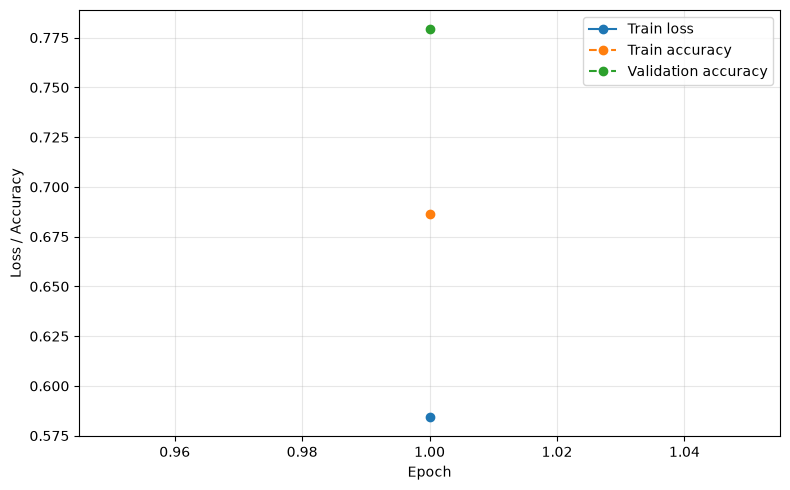

KeyboardInterrupt: 

In [4]:
device = get_device()

# move model to device
net = net.to(device)

loss = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr =1e-3)

training_output = StringIO()
status_display = display(
    {"text/plain": f"Training on: {device}\nStarting the first epoch..."},
    raw=True, display_id=True,
)

fig, ax = plt.subplots(figsize=(8, 5))
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss / Accuracy")
ax.set_title("Curves update after each completed epoch")
plot_display = display(fig, display_id=True)
plt.close(fig)


def update_progress(progress):
    """Show running training metrics before the epoch finishes."""
    message = (
        f"Epoch {progress['epoch']:02d} | "
        f"Batch {progress['batch']}/{progress['num_batches']} | "
        f"Train loss: {progress['loss']:.3f} | "
        f"Train accuracy: {progress['accuracy']:.3f}\n"
    )
    status_display.update(
        {"text/plain": message + training_output.getvalue()}, raw=True
    )


def update_plot(history):
    """Refresh the training curves after each epoch."""
    latest = history[-1]
    message = (
        f"Epoch {latest['epoch']:02d} | "
        f"Train loss: {latest['train']['loss']:.3f} | "
        f"Train accuracy: {latest['train']['accuracy']:.3f} | "
        f"Val accuracy: {latest['val']['accuracy']:.3f}\n"
    )
    status_display.update(
        {"text/plain": message + training_output.getvalue()}, raw=True
    )
    plot_history(history, ax=ax)
    ax.set_title("")
    plot_display.update(fig)


with redirect_stdout(training_output):
    metric_history = train_model(
        model=net,
        train_loader=train_set,
        val_loader=val_set,
        loss_fn=loss,
        optimizer=optimizer,
        num_epochs=20,
        device=device,
        on_epoch_end=update_plot,
        on_batch_end=update_progress,
    )

last_metrics = metric_history[-1]
final_results = (
    f"Train loss: {last_metrics['train']['loss']:.3f} | "
    f"Train accuracy: {last_metrics['train']['accuracy']:.3f} | "
    f"Val accuracy: {last_metrics['val']['accuracy']:.3f}\n"
)
status_display.update(
    {"text/plain": final_results + training_output.getvalue()}, raw=True
)